# Task : Daily Water Consumption Forecasting
#### in Phase 2 - Module 3: Time Series Data Analysis

### Environment setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from statsforecast import StatsForecast
from statsforecast.models import Naive, WindowAverage, AutoARIMA
from utilsforecast.losses import mae, rmse, mape
from utilsforecast.evaluation import evaluate
from utilsforecast.plotting import plot_series

## initial setup & Load Data
Load the CSV file, convert `Date` to datetime.

In [2]:
df = pd.read_csv("daily_water_consumption.csv", parse_dates=["Date"])
df = df.sort_values(["Zone", "Date"])
df = df.set_index("Date")

df.head(15)

,Zone,Residential_Usage,Commercial_Usage,Industrial_Usage,Leakage_Estimate,Pressure_Avg
Date,,,,,,
2024-01-01,ZONE_A,12500,8750,5430,450,2.85
2024-01-02,ZONE_A,13200,9120,5850,520,2.82
2024-01-03,ZONE_A,11800,8450,5200,480,2.90
2024-01-04,ZONE_A,14200,10000,6500,650,2.78
2024-01-05,ZONE_A,15800,11200,7200,750,2.75
2024-01-06,ZONE_A,10200,6800,4100,380,2.88
2024-01-07,ZONE_A,10800,7200,4500,420,2.90
2024-01-08,ZONE_A,13500,9500,5900,580,2.82
2024-01-09,ZONE_A,14200,10200,6400,650,2.78


## Ensure daily frequency per zone

In [3]:
zone_daily = {}

for zone, zone_df in df.groupby("Zone"):
    zone_daily[zone] = zone_df.sort_index().asfreq("D")

zones = sorted(zone_daily.keys())
daily_df = pd.concat(zone_daily, names=["Zone", "Date"])

## Check for missing values


In [4]:
print("Missing values after setting daily frequency:")
daily_df.isna().sum()

Missing values after setting daily frequency:


Zone                 0
Residential_Usage    0
Commercial_Usage     0
Industrial_Usage     0
Leakage_Estimate     0
Pressure_Avg         0
dtype: int64

## Plot Residential_Usage trends per zone

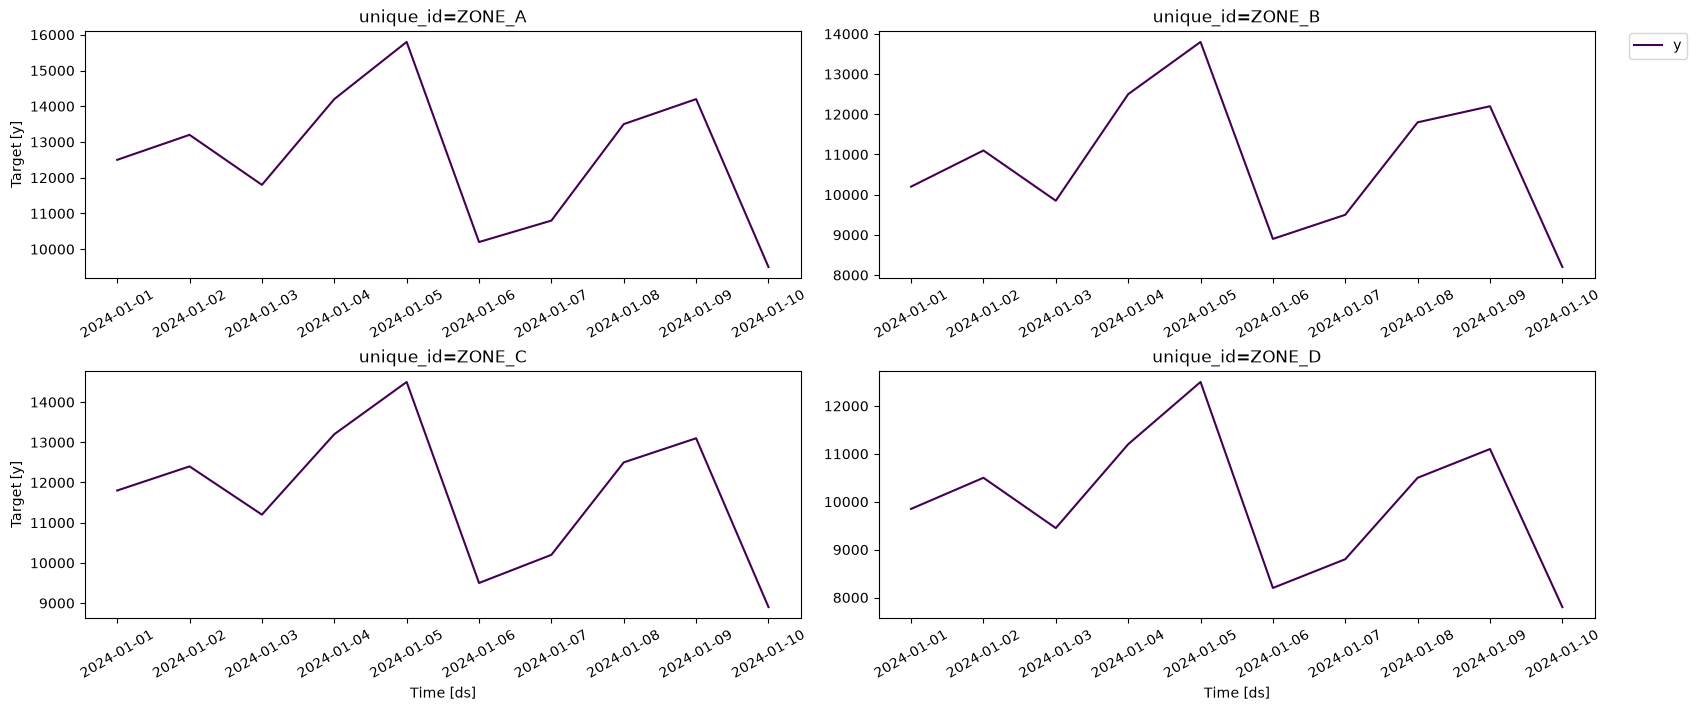

In [5]:
plot_df = df.reset_index().rename(columns={'Date': 'ds', 'Zone': 'unique_id', 'Residential_Usage': 'y'})
plot_series(df=plot_df, palette='viridis')

## Baseline Models
We use the last 7 rows per zone as test (the forecast horizon) and the first 3 rows as train.

In [6]:
# Build StatsForecast dataframe
sf_df = (
    df.reset_index()
    .rename(columns={"Date": "ds", "Zone": "unique_id", "Residential_Usage": "y"})
    [["unique_id", "ds", "y", "Pressure_Avg", "Leakage_Estimate"]]
    .sort_values(["unique_id", "ds"])
    .reset_index(drop=True)
)

horizon = 7
test = sf_df.groupby("unique_id").tail(horizon)
train = sf_df.drop(test.index).reset_index(drop=True)

## Apply naive forecast (previous day value)

In [7]:
sf_naive = StatsForecast(models=[Naive()], freq='D')
sf_naive.fit(df=train[['unique_id', 'ds', 'y']])
naive_preds = sf_naive.predict(h=horizon)
naive_preds.head()

,unique_id,ds,Naive
0,ZONE_A,2024-01-04,11800.0
1,ZONE_A,2024-01-05,11800.0
2,ZONE_A,2024-01-06,11800.0
3,ZONE_A,2024-01-07,11800.0
4,ZONE_A,2024-01-08,11800.0


## Apply moving average forecast
> window_size=2 uses the last 2 training values, giving more windows than window_size=3 with only 3 training days.

In [8]:
sf_ma = StatsForecast(models=[WindowAverage(window_size=2)], freq='D')
sf_ma.fit(df=train[['unique_id', 'ds', 'y']])
ma_preds = sf_ma.predict(h=horizon)
ma_preds.head()

,unique_id,ds,WindowAverage
0,ZONE_A,2024-01-04,12500.0
1,ZONE_A,2024-01-05,12500.0
2,ZONE_A,2024-01-06,12500.0
3,ZONE_A,2024-01-07,12500.0
4,ZONE_A,2024-01-08,12500.0


## Compute MAE and RMSE for baseline models

In [9]:
naive_eval_df = test[['unique_id', 'ds', 'y']].merge(naive_preds, on=['unique_id', 'ds'], how='left')
ma_eval_df    = test[['unique_id', 'ds', 'y']].merge(ma_preds,    on=['unique_id', 'ds'], how='left')

naive_eval = evaluate(naive_eval_df, metrics=[mae, rmse]).drop('unique_id', axis=1).groupby('metric').mean().reset_index()
ma_eval    = evaluate(ma_eval_df,    metrics=[mae, rmse]).drop('unique_id', axis=1).groupby('metric').mean().reset_index()

print(naive_eval.to_string(index=False))
print()
print(ma_eval.to_string(index=False))

metric       Naive
   mae 1921.428571
  rmse 2100.661009

metric  WindowAverage
   mae    1833.928571
  rmse    1967.824238


## Bar chart MAE&RMSE per baseline model

C:\Users\jc\AppData\Local\Temp\ipykernel_8092\159878523.py:4: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  float(naive_eval[naive_eval['metric']=='mae']['Naive']),
C:\Users\jc\AppData\Local\Temp\ipykernel_8092\159878523.py:5: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  float(ma_eval[ma_eval['metric']=='mae']['WindowAverage']),
C:\Users\jc\AppData\Local\Temp\ipykernel_8092\159878523.py:8: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  float(naive_eval[naive_eval['metric']=='rmse']['Naive']),
C:\Users\jc\AppData\Local\Temp\ipykernel_8092\159878523.py:9: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead


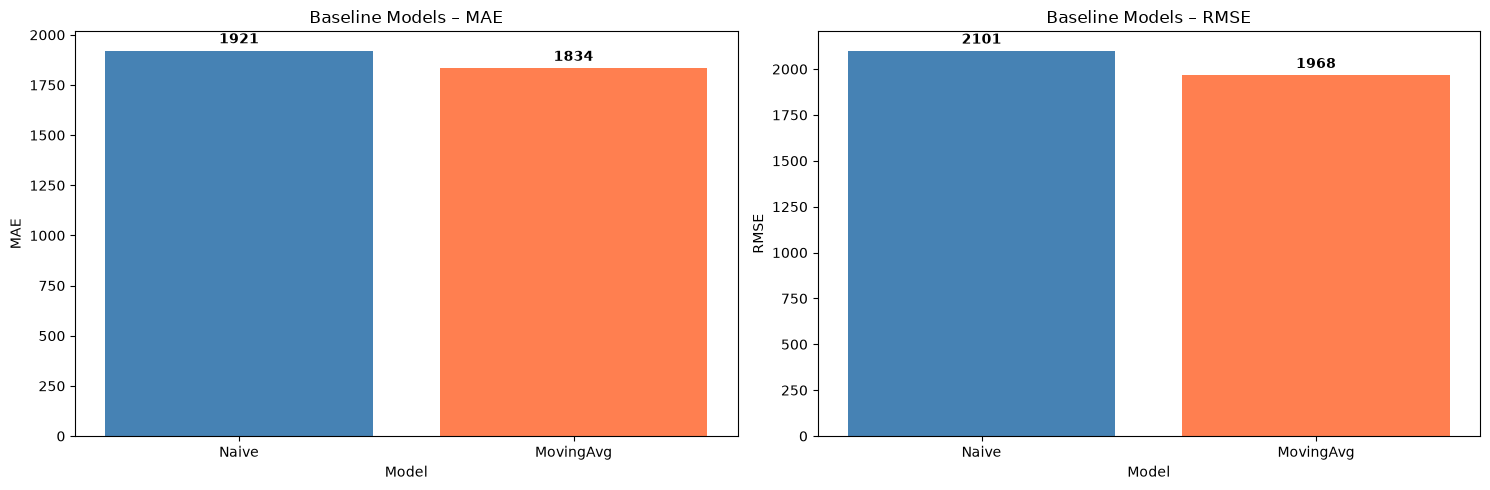

In [10]:
# Bar charts – MAE and RMSE per baseline model side-by-side
models_names = ['Naive', 'MovingAvg']
mae_vals = [
    float(naive_eval[naive_eval['metric']=='mae']['Naive']),
    float(ma_eval[ma_eval['metric']=='mae']['WindowAverage']),
]
rmse_vals = [
    float(naive_eval[naive_eval['metric']=='rmse']['Naive']),
    float(ma_eval[ma_eval['metric']=='rmse']['WindowAverage']),
]

# Sort data for MAE
sorted_mae = sorted(zip(models_names, mae_vals), key=lambda x: x[1], reverse=True)
ms_mae, vs_mae = zip(*sorted_mae)

# Sort data for RMSE
sorted_rmse = sorted(zip(models_names, rmse_vals), key=lambda x: x[1], reverse=True)
ms_rmse, vs_rmse = zip(*sorted_rmse)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot MAE
bars_mae = axes[0].bar(ms_mae, vs_mae, color=['steelblue', 'coral'])
for bar, v in zip(bars_mae, vs_mae):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
                 f'{v:.0f}', ha='center', va='bottom', fontweight='bold')
axes[0].set_title('Baseline Models – MAE')
axes[0].set_xlabel('Model')
axes[0].set_ylabel('MAE')

# Plot RMSE
bars_rmse = axes[1].bar(ms_rmse, vs_rmse, color=['steelblue', 'coral'])
for bar, v in zip(bars_rmse, vs_rmse):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
                 f'{v:.0f}', ha='center', va='bottom', fontweight='bold')
axes[1].set_title('Baseline Models – RMSE')
axes[1].set_xlabel('Model')
axes[1].set_ylabel('RMSE')

plt.tight_layout()
plt.show()

## Fit ARIMA model to each zone's Residential_Usage

In [11]:
arima_models = [
    AutoARIMA(seasonal=False, alias='ARIMA'),
    AutoARIMA(season_length=7, alias='SARIMA'),
]

sf_arima = StatsForecast(models=arima_models, freq='D')
sf_arima.fit(df=train[['unique_id', 'ds', 'y']])

C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsforecast\arima.py:1104: RuntimeWarning: divide by zero encountered in scalar divide
  fit["sigma2"] = np.nansum(fit["residuals"] ** 2) / (nstar - npar + 1)


C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsforecast\arima.py:1104: RuntimeWarning: divide by zero encountered in scalar divide
  fit["sigma2"] = np.nansum(fit["residuals"] ** 2) / (nstar - npar + 1)


C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsforecast\arima.py:1104: RuntimeWarning: divide by zero encountered in scalar divide
  fit["sigma2"] = np.nansum(fit["residuals"] ** 2) / (nstar - npar + 1)
C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsforecast\arima.py:1104: RuntimeWarning: divide by zero encountered in scalar divide
  fit["sigma2"] = np.nansum(fit["residuals"] ** 2) / (nstar - npar + 1)


StatsForecast(models=[ARIMA,SARIMA])

## Forecast next 7 days

In [12]:
arima_preds = sf_arima.predict(h=horizon)
arima_preds

,unique_id,ds,ARIMA,SARIMA
0,ZONE_A,2024-01-04,12500.000000,12500.000000
1,ZONE_A,2024-01-05,12500.000000,12500.000000
2,ZONE_A,2024-01-06,12500.000000,12500.000000
3,ZONE_A,2024-01-07,12500.000000,12500.000000
4,ZONE_A,2024-01-08,12500.000000,12500.000000
5,ZONE_A,2024-01-09,12500.000000,12500.000000
6,ZONE_A,2024-01-10,12500.000000,12500.000000
7,ZONE_B,2024-01-04,11333.330078,11333.330078
8,ZONE_B,2024-01-05,9791.672852,9791.672852
9,ZONE_B,2024-01-06,11333.322266,11333.322266


## Plot predicted vs actual values


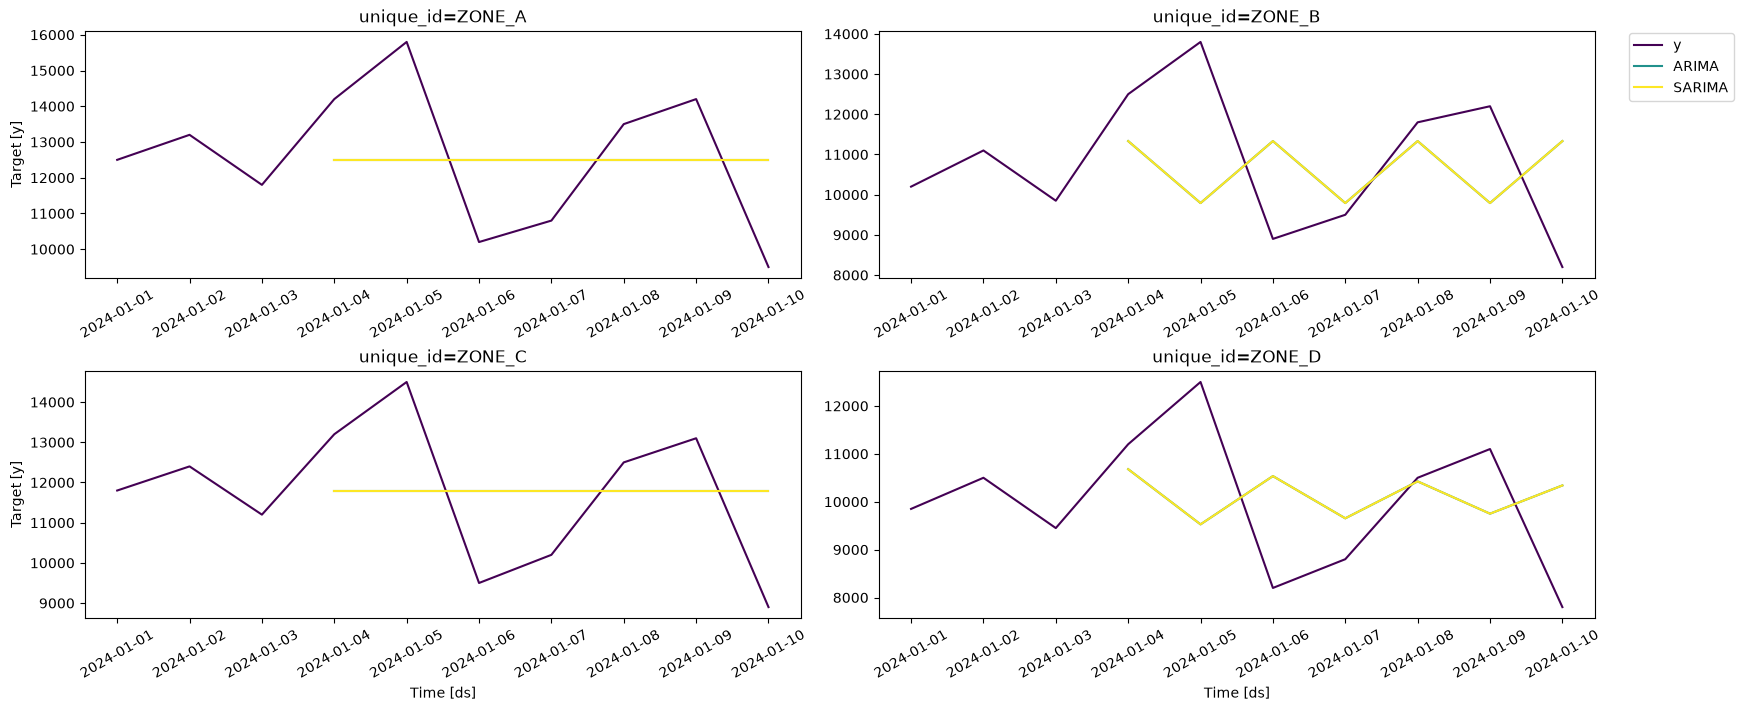

In [13]:
plot_series(
    df=sf_df,
    forecasts_df=arima_preds,
    max_insample_length=10,
    palette='viridis'
)

## Apply rolling window cross-validation

In [14]:
# window_size=2 to match training-set size (3 days)
cv_models = [
    Naive(alias='Naive'),
    WindowAverage(window_size=2, alias='MovingAvg'),
    AutoARIMA(seasonal=False, alias='ARIMA'),
    AutoARIMA(season_length=7, alias='SARIMA'),
]

sf_cv = StatsForecast(models=cv_models, freq='D')
cv_df = sf_cv.cross_validation(
    h=horizon,
    df=sf_df[['unique_id', 'ds', 'y']],
    n_windows=1,
    step_size=horizon,
    refit=True,
)
cv_df.head(8)

C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsforecast\arima.py:1104: RuntimeWarning: divide by zero encountered in scalar divide
  fit["sigma2"] = np.nansum(fit["residuals"] ** 2) / (nstar - npar + 1)


C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsforecast\arima.py:1104: RuntimeWarning: divide by zero encountered in scalar divide
  fit["sigma2"] = np.nansum(fit["residuals"] ** 2) / (nstar - npar + 1)


C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsforecast\arima.py:1104: RuntimeWarning: divide by zero encountered in scalar divide
  fit["sigma2"] = np.nansum(fit["residuals"] ** 2) / (nstar - npar + 1)
C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsforecast\arima.py:1104: RuntimeWarning: divide by zero encountered in scalar divide
  fit["sigma2"] = np.nansum(fit["residuals"] ** 2) / (nstar - npar + 1)


,unique_id,ds,cutoff,y,Naive,MovingAvg,ARIMA,SARIMA
0,ZONE_A,2024-01-04,2024-01-03,14200.0,11800.0,12500.0,12500.000000,12500.000000
1,ZONE_A,2024-01-05,2024-01-03,15800.0,11800.0,12500.0,12500.000000,12500.000000
2,ZONE_A,2024-01-06,2024-01-03,10200.0,11800.0,12500.0,12500.000000,12500.000000
3,ZONE_A,2024-01-07,2024-01-03,10800.0,11800.0,12500.0,12500.000000,12500.000000
4,ZONE_A,2024-01-08,2024-01-03,13500.0,11800.0,12500.0,12500.000000,12500.000000
5,ZONE_A,2024-01-09,2024-01-03,14200.0,11800.0,12500.0,12500.000000,12500.000000
6,ZONE_A,2024-01-10,2024-01-03,9500.0,11800.0,12500.0,12500.000000,12500.000000
7,ZONE_B,2024-01-04,2024-01-03,12500.0,9850.0,10475.0,11333.330078,11333.330078


## Evaluate performance with MAE, RMSE, MAPE

In [15]:
cv_eval = evaluate(
    cv_df.drop('cutoff', axis=1),
    metrics=[mae, rmse, mape],
)
cv_eval = cv_eval.drop('unique_id', axis=1).groupby('metric').mean().reset_index()
cv_eval

,metric,Naive,MovingAvg,ARIMA,SARIMA
0,mae,1921.428558,1833.928589,1862.695007,1862.695007
1,mape,0.166424,0.167807,0.172172,0.172172
2,rmse,2100.661011,1967.824249,2105.895935,2105.895935


## Bar chart CV metrics per model

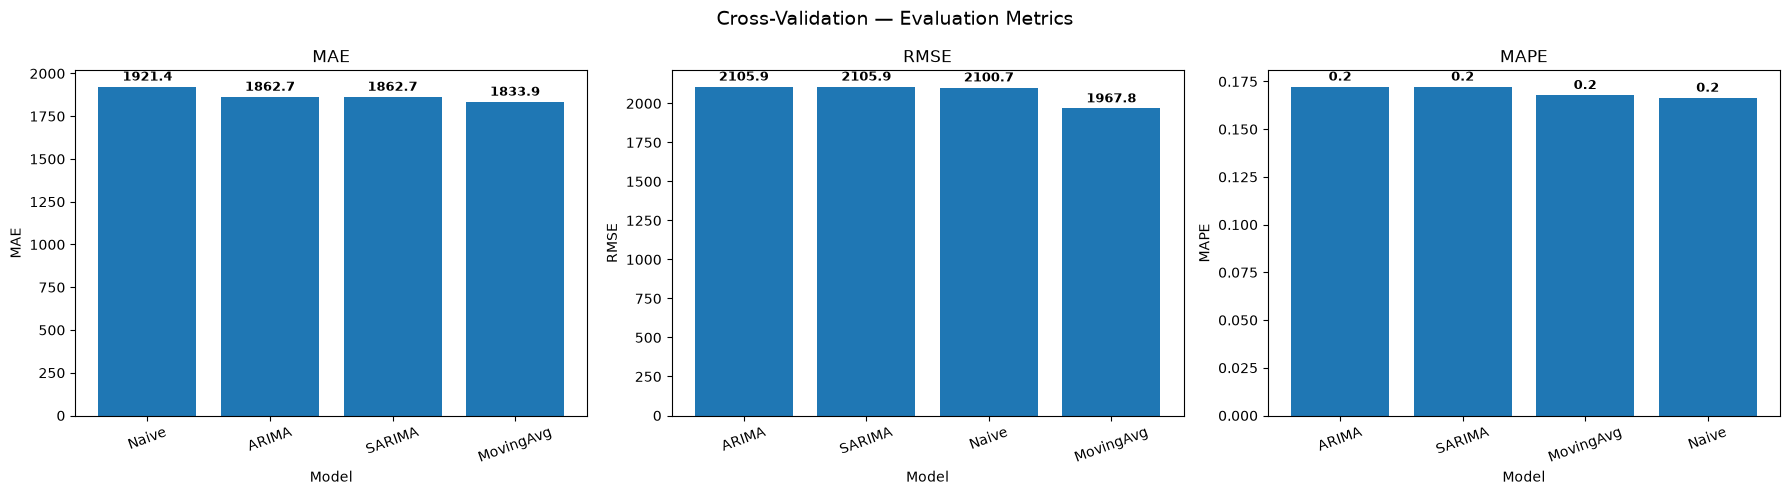

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
metric_names = ['mae', 'rmse', 'mape']

for ax, metric in zip(axes, metric_names):
    row = cv_eval[cv_eval['metric'] == metric].iloc[0]
    ms  = list(row.index[1:])
    vs  = list(row.values[1:].astype(float))
    sd  = sorted(zip(ms, vs), key=lambda x: x[1], reverse=True)
    ms_s, vs_s = zip(*sd)
    bars = ax.bar(ms_s, vs_s)
    for bar, v in zip(bars, vs_s):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.01,
                f'{v:.1f}', ha='center', va='bottom', fontweight='bold', fontsize=9)
    ax.set_title(metric.upper()); ax.set_xlabel('Model'); ax.set_ylabel(metric.upper())
    ax.tick_params(axis='x', rotation=20)

plt.suptitle('Cross-Validation — Evaluation Metrics', fontsize=14)
plt.tight_layout(); plt.show()

## (Optional) Include exogenous features
 (Pressure_Avg, Leakage_Estimate) in ARIMA.

In [17]:
train_exog = train[['unique_id', 'ds', 'y', 'Pressure_Avg', 'Leakage_Estimate']]
futr_exog  = test[['unique_id', 'ds', 'Pressure_Avg', 'Leakage_Estimate']]

sf_exog = StatsForecast(models=[AutoARIMA(season_length=7, alias='SARIMA_exog')], freq='D')
sf_exog.fit(df=train_exog)
exog_preds = sf_exog.predict(h=horizon, X_df=futr_exog)

exog_eval_df = test[['unique_id', 'ds', 'y']].merge(exog_preds, on=['unique_id', 'ds'], how='left')
exog_eval = evaluate(exog_eval_df, metrics=[mae, rmse])
exog_eval = exog_eval.drop('unique_id', axis=1).groupby('metric').mean().reset_index()
exog_eval

C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\regression\linear_model.py:1717: RuntimeWarning: divide by zero encountered in scalar divide
  return np.dot(wresid, wresid) / self.df_resid
C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\regression\linear_model.py:1717: RuntimeWarning: divide by zero encountered in scalar divide
  return np.dot(wresid, wresid) / self.df_resid
C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsforecast\arima.py:1104: RuntimeWarning: divide by zero encountered in scalar divide
  fit["sigma2"] = np.nansum(fit["residuals"] ** 2) / (nstar - npar + 1)
C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\regression\linear_model.py:1717: RuntimeWarning: divide by zero encountered in scalar divide
  return np.dot(wresid, wresid) / self.df_resid
C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\regression\linear_

C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\regression\linear_model.py:1717: RuntimeWarning: divide by zero encountered in scalar divide
  return np.dot(wresid, wresid) / self.df_resid
C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\regression\linear_model.py:1717: RuntimeWarning: divide by zero encountered in scalar divide
  return np.dot(wresid, wresid) / self.df_resid
C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsforecast\arima.py:1104: RuntimeWarning: divide by zero encountered in scalar divide
  fit["sigma2"] = np.nansum(fit["residuals"] ** 2) / (nstar - npar + 1)
C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\regression\linear_model.py:1717: RuntimeWarning: divide by zero encountered in scalar divide
  return np.dot(wresid, wresid) / self.df_resid
C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\regression\linear_

C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\regression\linear_model.py:1717: RuntimeWarning: divide by zero encountered in scalar divide
  return np.dot(wresid, wresid) / self.df_resid
C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsforecast\arima.py:1104: RuntimeWarning: divide by zero encountered in scalar divide
  fit["sigma2"] = np.nansum(fit["residuals"] ** 2) / (nstar - npar + 1)
C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\regression\linear_model.py:1717: RuntimeWarning: divide by zero encountered in scalar divide
  return np.dot(wresid, wresid) / self.df_resid
C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\regression\linear_model.py:1717: RuntimeWarning: divide by zero encountered in scalar divide
  return np.dot(wresid, wresid) / self.df_resid
C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\regression\linear_

C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsforecast\arima.py:1104: RuntimeWarning: divide by zero encountered in scalar divide
  fit["sigma2"] = np.nansum(fit["residuals"] ** 2) / (nstar - npar + 1)
C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\regression\linear_model.py:1717: RuntimeWarning: divide by zero encountered in scalar divide
  return np.dot(wresid, wresid) / self.df_resid
C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\regression\linear_model.py:1717: RuntimeWarning: divide by zero encountered in scalar divide
  return np.dot(wresid, wresid) / self.df_resid


,metric,SARIMA_exog
0,mae,957.810245
1,rmse,1222.427548


## Generate prediction intervals and plot them

In [18]:
sf_pi = StatsForecast(models=[AutoARIMA(season_length=7)], freq='D')
sf_pi.fit(df=train[['unique_id', 'ds', 'y']])
pi_preds = sf_pi.predict(h=horizon, level=[80])
pi_preds.head()

C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsforecast\arima.py:1104: RuntimeWarning: divide by zero encountered in scalar divide
  fit["sigma2"] = np.nansum(fit["residuals"] ** 2) / (nstar - npar + 1)


C:\Users\jc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsforecast\arima.py:1104: RuntimeWarning: divide by zero encountered in scalar divide
  fit["sigma2"] = np.nansum(fit["residuals"] ** 2) / (nstar - npar + 1)


,unique_id,ds,AutoARIMA,AutoARIMA-lo-80,AutoARIMA-hi-80
0,ZONE_A,2024-01-04,12500.0,11602.914062,13397.085938
1,ZONE_A,2024-01-05,12500.0,11602.914062,13397.085938
2,ZONE_A,2024-01-06,12500.0,11602.914062,13397.085938
3,ZONE_A,2024-01-07,12500.0,11602.914062,13397.085938
4,ZONE_A,2024-01-08,12500.0,11602.914062,13397.085938


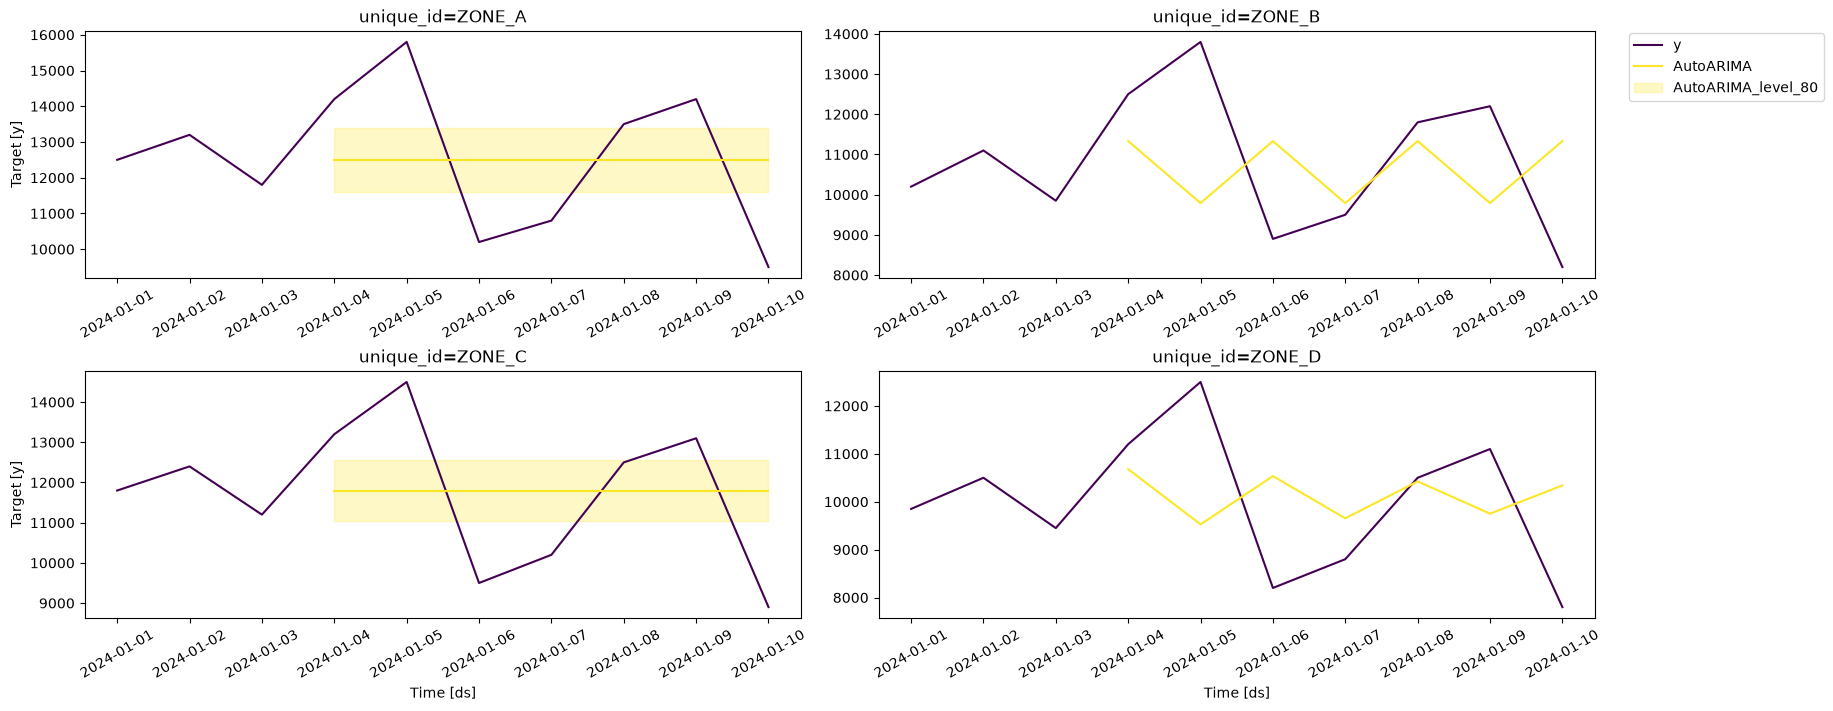

In [19]:
# Plot prediction intervals
plot_series(
    df=sf_df,
    forecasts_df=pi_preds,
    models=['AutoARIMA'],
    level=[80],
    max_insample_length=10,
    palette='viridis'
)

## Report best model per zone based on metrics.

In [20]:
cv_eval_per_zone = evaluate(
    cv_df.drop('cutoff', axis=1),
    metrics=[mae],
)
model_cols = [c for c in cv_eval_per_zone.columns if c not in ['unique_id', 'metric']]

best = (
    cv_eval_per_zone[cv_eval_per_zone['metric'] == 'mae']
    .set_index('unique_id')[model_cols]
    .idxmin(axis=1)
    .rename('Best Model')
)
print('Best model per zone (lowest MAE):')
print(best.to_string())

Best model per zone (lowest MAE):
unique_id
ZONE_A    MovingAvg
ZONE_B    MovingAvg
ZONE_C    MovingAvg
ZONE_D    MovingAvg


##  7-day forecast table for each zone.

In [21]:
#(trained on ALL data)
sf_final = StatsForecast(models=[AutoARIMA(season_length=7, alias='SARIMA')], freq='D')
sf_final.fit(df=sf_df[['unique_id', 'ds', 'y']])
future_preds = sf_final.predict(h=horizon)

forecast_table = future_preds.pivot(index='ds', columns='unique_id', values='SARIMA')
forecast_table.index.name = 'Date'
forecast_table.columns.name = None
forecast_table = forecast_table.round(0).astype(int)
print('7-Day Residential_Usage Forecast per Zone:')
forecast_table

7-Day Residential_Usage Forecast per Zone:


,ZONE_A,ZONE_B,ZONE_C,ZONE_D
Date,,,,
2024-01-11,12570,10805,11730,9990
2024-01-12,12570,10805,11730,9990
2024-01-13,12570,10805,11730,9990
2024-01-14,12570,10805,11730,9990
2024-01-15,12570,10805,11730,9990
2024-01-16,12570,10805,11730,9990
2024-01-17,12570,10805,11730,9990
